# 03 - Learning curves: NN supervised (cấp 5) và RL self-play (cấp 6)

Phụ trách: Người 3. Notebook này **chỉ đọc log thô** do `train/train_supervised.py` và `train/train_rl.py` ghi ra
(không gõ tay số liệu). Hình lưu vào `results/figures/`.

Trước khi chạy:
1. `python -m train.generate_data` -> `python -m train.train_supervised` (log ở `results/logs/train_supervised/<run>/`)
2. `python -m train.train_rl` (log ở `results/logs/train_rl/<run>/`)
3. Sửa `SUP_RUN`, `RL_RUN` bên dưới cho đúng tên thư mục log của lần chạy **chính thức**.

Câu hỏi nghiên cứu 3: *self-play RL có cải thiện so với mô hình bắt chước (NN supervised) không?*

In [1]:
import json, os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from eval.metrics import wilson_interval          # dùng chung độ đo với giải đấu

LOGS = Path(os.environ.get("LOGS_DIR", REPO / "results" / "logs"))
FIGS = Path(os.environ.get("FIG_DIR", REPO / "results" / "figures"))
FIGS.mkdir(parents=True, exist_ok=True)

SUP_RUN = "supervised_seed42"     # tên thư mục log supervised
RL_RUN = "rl_seed42"              # tên thư mục log RL
SUP = LOGS / "train_supervised_heuristic" / SUP_RUN
RL = LOGS / "train_rl_heuristic" / RL_RUN
print("supervised log:", SUP, "->", "có" if SUP.exists() else "CHƯA CÓ")
print("rl log        :", RL, "->", "có" if RL.exists() else "CHƯA CÓ")

supervised log: c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\logs\train_supervised_heuristic\supervised_seed42 -> có
rl log        : c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\logs\train_rl_heuristic\rl_seed42 -> có


## 1. NN supervised: loss và accuracy theo epoch

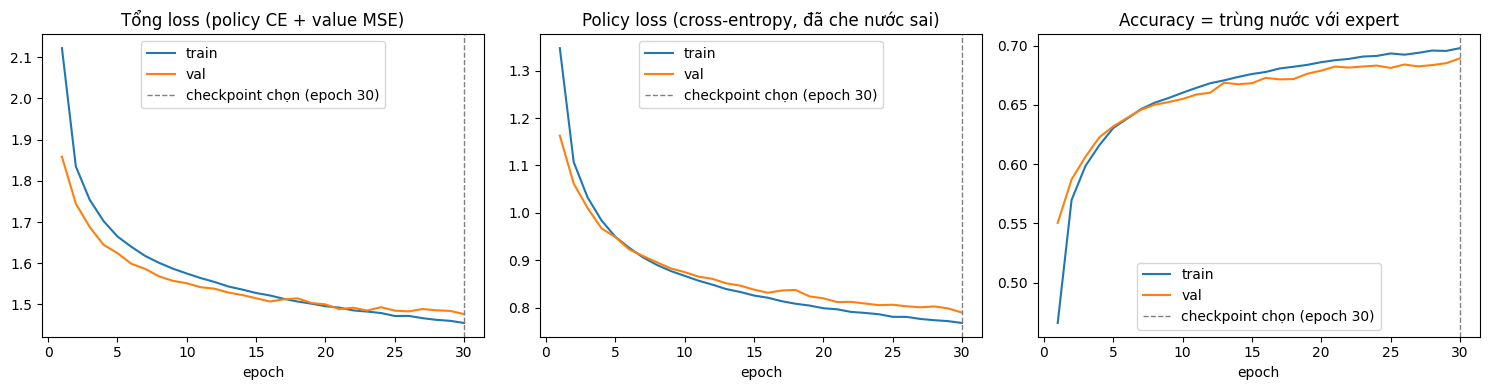

                             chỉ số  giá trị
test policy accuracy (trùng expert) 0.694216
  đoán ngẫu nhiên trong nước hợp lệ 0.189439
                     test value MSE 0.737378
          value MSE nếu luôn đoán 0 0.969946
 value MSE nếu luôn đoán trung bình 0.969908

Nguồn nhãn : {'expert_agent': 'heuristic', 'is_temporary_expert': False, 'note': 'policy = nước của expert; value = kết quả cuối ván theo góc nhìn người đang đi. Mô hình học từ dữ liệu này có nguy cơ chỉ học lại expert (đề mục 3.4).'}
Mẫu/split  : {'train': 239311, 'val': 29987, 'test': 29946}
Thiết bị   : cpu (Intel64 Family 6 Model 154 Stepping 3, GenuineIntel), thời gian train 1421.6s, 158,093 tham số, 30 epoch


In [2]:
if SUP.exists():
    ep = pd.read_csv(SUP / "epochs.csv")
    meta = json.load(open(SUP / "meta.json", encoding="utf-8"))
    test = json.load(open(SUP / "test_metrics.json", encoding="utf-8"))
    best = test["best_epoch"]

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for a, (col, title) in zip(ax, [("loss", "Tổng loss (policy CE + value MSE)"),
                                    ("policy_loss", "Policy loss (cross-entropy, đã che nước sai)"),
                                    ("acc", "Accuracy = trùng nước với expert")]):
        a.plot(ep.epoch, ep[f"train_{col}"], label="train")
        a.plot(ep.epoch, ep[f"val_{col}"], label="val")
        a.axvline(best, color="gray", ls="--", lw=1, label=f"checkpoint chọn (epoch {best})")
        a.set_xlabel("epoch"); a.set_title(title); a.legend()
    plt.tight_layout(); plt.savefig(FIGS / "03_supervised_curves.png", dpi=150); plt.show()

    t, b = test["test"], test["baselines"]
    print(pd.DataFrame({
        "chỉ số": ["test policy accuracy (trùng expert)", "đoán ngẫu nhiên trong nước hợp lệ",
                   "test value MSE", "value MSE nếu luôn đoán 0", "value MSE nếu luôn đoán trung bình"],
        "giá trị": [t["acc"], b["random_legal_move_accuracy"], t["value_loss"],
                    b["value_mse_predict_zero"], b["value_mse_predict_mean"]]}).to_string(index=False))
    print("\nNguồn nhãn :", meta["label_source"])
    print("Mẫu/split  :", meta["samples"])
    print(f"Thiết bị   : {meta['device']} ({meta['gpu'] or meta['cpu']}), thời gian train {meta['train_seconds']}s, "
          f"{meta['n_params']:,} tham số, {meta['epochs']} epoch")
else:
    print("Chưa có log supervised.")

**Cách đọc**: `train` thấp hơn `val` nhiều => overfit. Accuracy là tỷ lệ chọn đúng nước của *expert*, không phải
độ mạnh thật: mạng chỉ bắt chước nên không thể vượt expert quá nhiều (rủi ro "học lại heuristic", đề mục 3.4).
Phải đọc cùng với kết quả giải đấu (notebook 01).

## 2. RL self-play: chẩn đoán huấn luyện

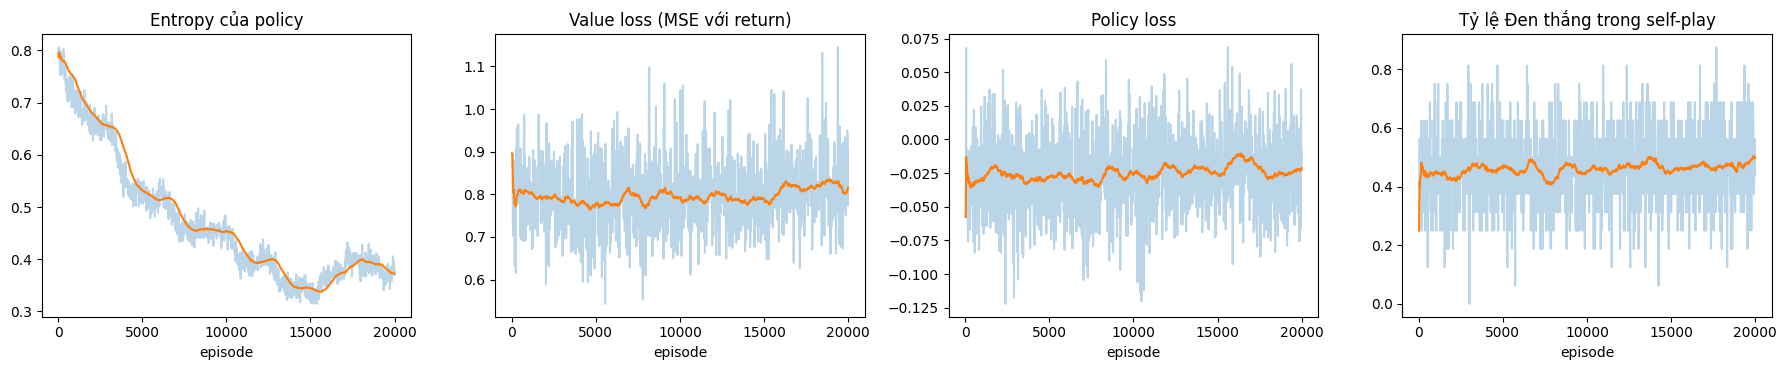

Khởi tạo từ: checkpoints/nn_supervised_heuristic.pt | 20000 ván self-play | 1939.3s trên Intel64 Family 6 Model 154 Stepping 3, GenuineIntel | 158,093 tham số


In [3]:
if RL.exists():
    tl = pd.read_csv(RL / "train_log.csv")
    rmeta = json.load(open(RL / "meta.json", encoding="utf-8"))
    w = max(1, len(tl) // 20)                       # cửa sổ làm mượt
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
    for a, (col, title) in zip(ax, [("entropy", "Entropy của policy"), ("value_loss", "Value loss (MSE với return)"),
                                    ("policy_loss", "Policy loss"), ("black_win_rate", "Tỷ lệ Đen thắng trong self-play")]):
        a.plot(tl.episodes, tl[col], alpha=0.3)
        a.plot(tl.episodes, tl[col].rolling(w, min_periods=1).mean())
        a.set_xlabel("episode"); a.set_title(title)
    plt.tight_layout(); plt.savefig(FIGS / "03_rl_training_diagnostics.png", dpi=150); plt.show()
    print(f"Khởi tạo từ: {rmeta['init_from']} | {rmeta['episodes']} ván self-play | "
          f"{rmeta['train_seconds']}s trên {rmeta['gpu'] or rmeta['cpu']} | {rmeta['n_params']:,} tham số")
    if rmeta["opponents_skipped"]:
        print("ĐỐI THỦ BỊ BỎ QUA khi train (chưa dùng được):", rmeta["opponents_skipped"])
else:
    print("Chưa có log RL.")

Entropy giảm quá nhanh về 0 = policy co cụm sớm (cân nhắc tăng `entropy_coef`). Value loss không giảm = đầu value
chưa dự đoán được kết quả (baseline kém nên gradient nhiễu).

## 3. RL: learning curve (đấu đối thủ cố định, khai cuộc/seed riêng)

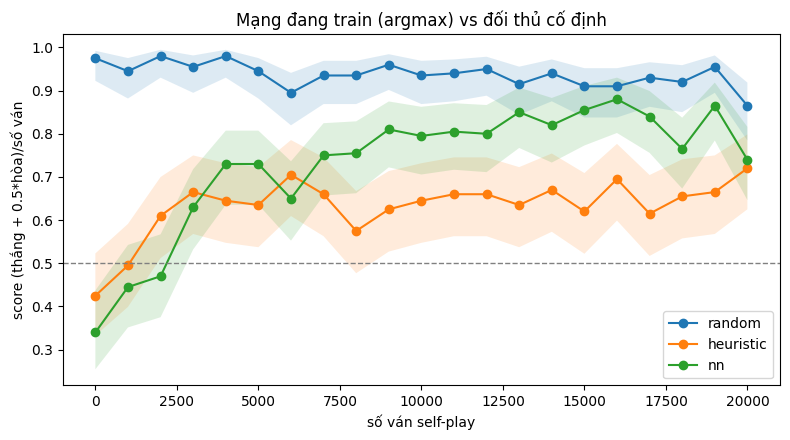

Số ván mỗi điểm: 100 (dải mờ = khoảng tin cậy Wilson 95%, xấp xỉ khi có hòa)


In [4]:
if RL.exists():
    lc = pd.read_csv(RL / "learning_curve.csv")
    lo_hi = lc.apply(lambda r: wilson_interval(r.wins + 0.5 * r.draws, r.games), axis=1)
    lc["lo"], lc["hi"] = [x[0] for x in lo_hi], [x[1] for x in lo_hi]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for opp, g in lc.groupby("opponent", sort=False):
        ax.plot(g.episodes, g.score, marker="o", label=opp)
        ax.fill_between(g.episodes, g.lo, g.hi, alpha=0.15)
    ax.axhline(0.5, color="gray", ls="--", lw=1)
    ax.set_xlabel("số ván self-play"); ax.set_ylabel("score (thắng + 0.5*hòa)/số ván")
    ax.set_title("Mạng đang train (argmax) vs đối thủ cố định"); ax.legend()
    plt.tight_layout(); plt.savefig(FIGS / "03_rl_learning_curve.png", dpi=150); plt.show()
    print("Số ván mỗi điểm:", int(lc.games.iloc[0]), "(dải mờ = khoảng tin cậy Wilson 95%, xấp xỉ khi có hòa)")
else:
    print("Chưa có log RL.")

## 4. Câu hỏi 3: RL so với NN supervised

In [5]:
if RL.exists():
    first, last = lc.episodes.min(), lc.episodes.max()
    rows = []
    for opp, g in lc.groupby("opponent", sort=False):
        a, b = g[g.episodes == first].iloc[0], g[g.episodes == last].iloc[0]
        rows.append({"đối thủ": opp, f"score @ {first}": a.score, f"score @ {last}": b.score,
                     "thay đổi": b.score - a.score,
                     f"CI95 @ {last}": f"[{b.lo:.2f}, {b.hi:.2f}]", "ván/điểm": int(b.games)})
    print(pd.DataFrame(rows).round(3).to_string(index=False))
    if "nn" in set(lc.opponent):
        g = lc[lc.opponent == "nn"].iloc[-1]
        print(f"\nRL cuối vs NN supervised: score {g.score:.3f}, CI95 [{g.lo:.2f}, {g.hi:.2f}] "
              f"({int(g.wins)}W/{int(g.draws)}D/{int(g.losses)}L). "
              + ("CI chứa 0.5 => chưa đủ bằng chứng RL hơn/kém NN ở số ván này." if g.lo <= 0.5 <= g.hi
                 else "CI không chứa 0.5."))

  đối thủ  score @ 0  score @ 20000  thay đổi CI95 @ 20000  ván/điểm
   random      0.975          0.865    -0.110 [0.78, 0.92]       100
heuristic      0.425          0.720     0.295 [0.63, 0.80]       100
       nn      0.340          0.740     0.400 [0.65, 0.82]       100

RL cuối vs NN supervised: score 0.740, CI95 [0.65, 0.82] (74W/0D/26L). CI không chứa 0.5.


### Kết luận (điền SAU KHI đọc số liệu ở trên, không điền trước)

- RL có cải thiện so với NN supervised không? Dựa trên con số nào (score vs `nn`, vs `random`, vs đối thủ mạnh nhất)?
- Nguyên nhân khả dĩ của kết quả (số ván self-play, mạng nhỏ, reward thưa chỉ ở cuối ván, expert nhãn là gì).
- Hạn chế: số ván/điểm đánh giá, một seed, đối thủ cố định chỉ là proxy, điểm này khác với giải đấu chính thức (notebook 01).
- Nếu đối thủ `heuristic` bị bỏ qua khi train: ghi rõ trong báo cáo.